# James Torres
## CSCI E-89 Assignment 03, Problem 5

Build and train a PyTorch FashionMNIST image classifier with two hidden layers, plot its learning progress, and evaluate its predictions. This notebook contains the full implementation and trains for 20 epochs without importing any project scripts.

Based on the image-classifier example in chapter 10 of Aurélien Géron's *Hands-On Machine Learning with Scikit-Learn and PyTorch* (2025). [Author's reference notebook](https://github.com/ageron/handson-mlp/blob/main/10_neural_nets_with_pytorch.ipynb). Install dependencies from `requirements.txt` before running; the first run downloads FashionMNIST.

### 1. Prepare FashionMNIST
Define the float32 image transform, seed the 55,000/5,000 split, build batch-32 loaders, and select CUDA, MPS, or CPU.

In [1]:
"""Download FashionMNIST, make the seeded split, and inspect a batch."""

import torch
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import FashionMNIST
from torchvision.transforms import v2 as T


def get_device():
    """Prefer CUDA, then Apple MPS, and otherwise use the CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def load_data():
    # Convert PIL images into float32 tensors with pixels scaled to [0, 1].
    transform = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])
    full_train = FashionMNIST(root="datasets", train=True, download=True, transform=transform)
    test_set = FashionMNIST(root="datasets", train=False, download=True, transform=transform)
    torch.manual_seed(42)
    train_set, valid_set = random_split(full_train, [55_000, 5_000])
    # Only training batches are shuffled; validation/test order stays fixed.
    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=32)
    test_loader = DataLoader(test_set, batch_size=32)
    return train_loader, valid_loader, test_loader, full_train.classes

Download the data and verify the split sizes, disjoint subsets, image shape, dtype, and pixel range.

In [2]:
# Inspect one training batch and check the data contract.
train_loader, valid_loader, test_loader, classes = load_data()
images, labels = next(iter(train_loader))
assert [len(loader.dataset) for loader in (train_loader, valid_loader, test_loader)] == [55_000, 5_000, 10_000]
assert images.shape == (32, 1, 28, 28) and images.dtype == torch.float32
assert 0 <= images.min() <= images.max() <= 1
assert set(train_loader.dataset.indices).isdisjoint(valid_loader.dataset.indices)
print(f"Device: {get_device()}")
print("Train: 55000; validation: 5000; test: 10000")
print(f"Batch: {tuple(images.shape)}, {images.dtype}; classes: {classes}")

Device: cpu
Train: 55000; validation: 5000; test: 10000
Batch: (32, 1, 28, 28), torch.float32; classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 2. Define the classifier
Flatten each image and apply dense layers of 300, 100, and 10 units, with ReLU between hidden layers. Return raw logits.

In [3]:
"""Define the chapter 10 dense image classifier."""

import torch
from torch import nn


class ImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        # CrossEntropyLoss expects raw logits, so omit a final softmax.
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 300),
            nn.ReLU(),
            nn.Linear(300, 100),
            nn.ReLU(),
            nn.Linear(100, 10),
        )

    def forward(self, images):
        return self.layers(images)

Count the trainable parameters and verify that three images produce a 3-by-10 logit tensor.

In [4]:
torch.manual_seed(42)
model = ImageClassifier()
parameter_count = sum(p.numel() for p in model.parameters())
# Check both the parameter total and the ten logits for each image.
assert parameter_count == 266_610
assert model(torch.zeros(3, 1, 28, 28)).shape == (3, 10)
print(model)
print(f"Parameter count: {parameter_count:,}")

ImageClassifier(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=300, bias=True)
    (2): ReLU()
    (3): Linear(in_features=300, out_features=100, bias=True)
    (4): ReLU()
    (5): Linear(in_features=100, out_features=10, bias=True)
  )
)
Parameter count: 266,610


### 3. Train and record learning progress
Define the training loop with TorchMetrics multiclass accuracy reset between phases and epochs. Weight loss by batch size so the final short batch is handled correctly. Save final weights and history. Training accuracy is measured during updates; validation uses the fixed weights at the end of each epoch.

In [5]:
"""Train for 20 epochs and save the final weights and learning history."""

import json
from pathlib import Path

import torch
from torch import nn
from torchmetrics import Accuracy



def train(model, optimizer, criterion, train_loader, valid_loader, device, n_epochs=20):
    """Track sample-weighted loss and epoch-level multiclass accuracies."""
    metric = Accuracy(task="multiclass", num_classes=10).to(device)
    history = {"train_loss": [], "train_accuracy": [], "valid_accuracy": []}
    for epoch in range(n_epochs):
        model.train()
        metric.reset()
        total_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            # Clear gradients before each update so batches do not accumulate.
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            metric.update(logits.detach(), labels)
        train_accuracy = metric.compute().item()
        metric.reset()
        model.eval()
        # Validation measures generalization without changing the weights.
        with torch.inference_mode():
            for images, labels in valid_loader:
                metric.update(model(images.to(device)), labels.to(device))
        valid_accuracy = metric.compute().item()
        metric.reset()
        history["train_loss"].append(total_loss / len(train_loader.dataset))
        history["train_accuracy"].append(train_accuracy)
        history["valid_accuracy"].append(valid_accuracy)
        print(f"Epoch {epoch + 1:02d}/{n_epochs}: "
              f"loss={history['train_loss'][-1]:.4f}, "
              f"train={train_accuracy:.4%}, valid={valid_accuracy:.4%}", flush=True)
    return history


def run_training():
    # One CPU thread avoids overhead for this small network and batch size.
    torch.set_num_threads(1)
    train_loader, valid_loader, _, _ = load_data()
    torch.manual_seed(42)
    device = get_device()
    model = ImageClassifier().to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
    history = train(model, optimizer, nn.CrossEntropyLoss(),
                    train_loader, valid_loader, device, n_epochs=20)
    Path("history.json").write_text(json.dumps(history, indent=2) + "\n", encoding="utf-8")
    # A CPU state_dict is portable when loaded on another device.
    torch.save({name: value.detach().cpu() for name, value in model.state_dict().items()}, "model.pt")
    return model, history

Train a fresh seeded model for all 20 epochs with SGD (learning rate 0.1) and cross-entropy. Save `history.json` and `model.pt` in the working directory.

In [6]:
# Reset data and model seeds for the same experiment as the training script.
model, history = run_training()
print(f"Final validation accuracy: {history['valid_accuracy'][-1]:.4%}")

Epoch 01/20: loss=0.6060, train=78.1782%, valid=84.1600%


Epoch 02/20: loss=0.4058, train=84.9836%, valid=84.1600%


Epoch 03/20: loss=0.3630, train=86.5764%, valid=85.2000%


Epoch 04/20: loss=0.3353, train=87.7109%, valid=86.3800%


Epoch 05/20: loss=0.3143, train=88.3964%, valid=87.9600%


Epoch 06/20: loss=0.2991, train=88.7327%, valid=86.4000%


... (11 outputs left out)

Epoch 18/20: loss=0.1985, train=92.3545%, valid=88.5800%


Epoch 19/20: loss=0.1942, train=92.6218%, valid=88.6200%


Epoch 20/20: loss=0.1878, train=92.8582%, valid=87.2800%


Final validation accuracy: 87.2800%


### 4. Plot accuracy
Define a labeled plot comparing training and validation accuracy across epochs; also save it as a PNG.

In [7]:
"""Plot the recorded training and validation accuracies."""

import json
from pathlib import Path

import matplotlib.pyplot as plt


def plot_accuracy(history):
    # Show both curves on the same scale to compare fitting and generalization.
    epochs = range(1, len(history["train_accuracy"]) + 1)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(epochs, history["train_accuracy"], "o-", label="Training accuracy")
    ax.plot(epochs, history["valid_accuracy"], "s-", label="Validation accuracy")
    ax.set(title="FashionMNIST: Training and Validation Accuracy",
           xlabel="Epoch", ylabel="Accuracy", ylim=(0.7, 1.0))
    ax.set_xticks(list(epochs))
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig("training_accuracy.png", dpi=150)
    return fig

Render the accuracy plot inline and save `training_accuracy.png`.

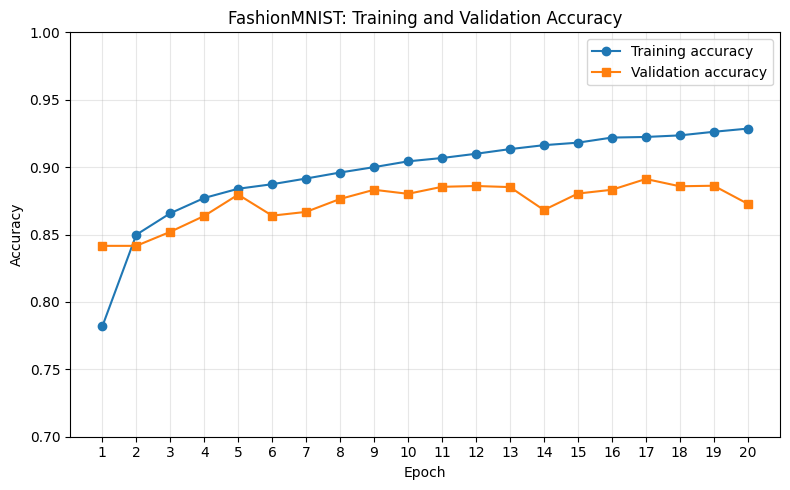

In [8]:
# Use Jupyter's inline backend so the executed notebook embeds the figure.
%matplotlib inline
figure = plot_accuracy(history)
plt.show()

### 5. Evaluate the final model
Compute accuracy on the untouched test set and inspect the first three validation images. Show true and predicted labels, all ten softmax probabilities to three decimals, and the four most probable classes.

In [9]:
"""Evaluate the final checkpoint and inspect three validation predictions."""

import json
from pathlib import Path

import torch
from torchmetrics import Accuracy



def evaluate(model, valid_loader, test_loader, classes, device):
    model.eval()
    metric = Accuracy(task="multiclass", num_classes=10).to(device)
    metric.reset()
    with torch.inference_mode():
        for images, labels in test_loader:
            metric.update(model(images.to(device)), labels.to(device))
        test_accuracy = metric.compute().item()
        metric.reset()
        # Index the validation subset directly to preserve its first three images.
        examples = [valid_loader.dataset[index] for index in range(3)]
        images = torch.stack([image for image, _ in examples]).to(device)
        probabilities = model(images).softmax(dim=1).cpu()
        top_probabilities, top_indices = probabilities.topk(4, dim=1)
    assert torch.allclose(probabilities.sum(dim=1), torch.ones(3))
    print(f"Test accuracy: {test_accuracy:.4%}")
    print(f"Probability column order: {classes}")
    predictions = []
    for index, (_, label) in enumerate(examples):
        predicted = int(probabilities[index].argmax())
        top_four = [{"class": classes[int(class_id)], "probability": float(probability)}
                    for probability, class_id in zip(top_probabilities[index], top_indices[index])]
        print(f"\nValidation image {index + 1}: predicted={classes[predicted]} ({predicted}), "
              f"true={classes[label]} ({label})")
        print("Softmax: [" + ", ".join(f"{p:.3f}" for p in probabilities[index]) + "]")
        print("Top 4: " + ", ".join(f"{item['class']} ({item['probability']:.3f})" for item in top_four))
        predictions.append({"validation_index": index, "predicted_label": predicted,
                            "predicted_class": classes[predicted], "true_label": int(label),
                            "true_class": classes[label], "probabilities": probabilities[index].tolist(),
                            "top_4": top_four})
    # Preserve full precision in JSON; round only the displayed probabilities.
    result = {"test_accuracy": test_accuracy, "classes": classes, "predictions": predictions}
    Path("evaluation.json").write_text(json.dumps(result, indent=2) + "\n", encoding="utf-8")
    return result

Reload the final checkpoint and evaluate it. Save full-precision results to `evaluation.json`; only the printed probabilities are rounded.

In [10]:
# Evaluate the saved checkpoint using the same seeded validation subset.
torch.set_num_threads(1)
_, valid_loader, test_loader, classes = load_data()
device = get_device()
model = ImageClassifier().to(device)
model.load_state_dict(torch.load("model.pt", map_location=device, weights_only=True))
evaluate(model, valid_loader, test_loader, classes, device)

Test accuracy: 87.4200%
Probability column order: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Validation image 1: predicted=Sneaker (7), true=Sneaker (7)
Softmax: [0.000, 0.000, 0.000, 0.000, 0.000, 0.004, 0.000, 0.884, 0.000, 0.111]
Top 4: Sneaker (0.884), Ankle boot (0.111), Sandal (0.004), Bag (0.000)

Validation image 2: predicted=Coat (4), true=Coat (4)
Softmax: [0.000, 0.000, 0.002, 0.000, 0.998, 0.000, 0.000, 0.000, 0.000, 0.000]
Top 4: Coat (0.998), Pullover (0.002), Shirt (0.000), Bag (0.000)

Validation image 3: predicted=Pullover (2), true=Pullover (2)
Softmax: [0.000, 0.000, 0.672, 0.000, 0.210, 0.000, 0.118, 0.000, 0.000, 0.000]
Top 4: Pullover (0.672), Coat (0.210), Shirt (0.118), T-shirt/top (0.000)


{'test_accuracy': 0.8741999864578247,
 'classes': ['T-shirt/top',
  'Trouser',
  'Pullover',
  'Dress',
  'Coat',
  'Sandal',
  'Shirt',
  'Sneaker',
  'Bag',
  'Ankle boot'],
 'predictions': [{'validation_index': 0,
   'predicted_label': 7,
   'predicted_class': 'Sneaker',
   'true_label': 7,
   'true_class': 'Sneaker',
   'probabilities': [1.1433177860453725e-05,
    5.087539102532901e-05,
    2.095621084663435e-06,
    2.0954881620127708e-05,
    8.123814950522501e-06,
    0.003907111007720232,
    5.8811497183342e-06,
    0.8844508528709412,
    0.00017103341815527529,
    0.11137156188488007],
   'top_4': [{'class': 'Sneaker', 'probability': 0.8844508528709412},
    {'class': 'Ankle boot', 'probability': 0.11137156188488007},
    {'class': 'Sandal', 'probability': 0.003907111007720232},
    {'class': 'Bag', 'probability': 0.00017103341815527529}]},
  {'validation_index': 1,
   'predicted_label': 4,
   'predicted_class': 'Coat',
   'true_label': 4,
   'true_class': 'Coat',
   'prob

Display the three validation images alongside their true and predicted classes.

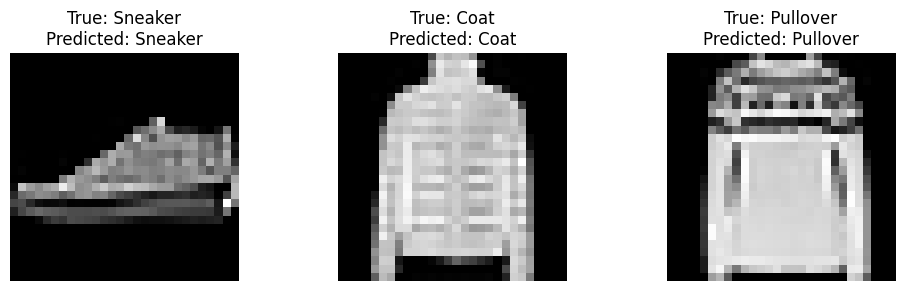

In [11]:
# Visualize the same examples used in the probability report.
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
with torch.inference_mode():
    for index, ax in enumerate(axes):
        image, label = valid_loader.dataset[index]
        predicted = model(image.unsqueeze(0).to(device)).argmax(dim=1).item()
        ax.imshow(image.squeeze().numpy(), cmap='gray')
        ax.set_title(f'True: {classes[label]}\nPredicted: {classes[predicted]}')
        ax.axis('off')
fig.tight_layout()
plt.show()